# MMA3001 | Formula 1 Next-Lap-Time Prediction
### Comparative Evaluation of Machine Learning Models for Formula 1 Lap Time Prediction and Race Strategy Analysis

**Engineering task:** At the end of lap *n*, predict the duration of **lap n+1**, conditional on the target being a normal consecutive racing lap in the same stint. This is a retrospective **clean-lap** experiment, **not** a prediction of safety cars, pit stops, DNFs or real-time reliability.

**Primary output:** `PredictedNextLapTime_s` (seconds); **regression target:** `DeltaLapTime_s = NextLapTime_s - PreviousLapTime_s`. Compare persistence, multiple linear regression, decision tree, and random forest. Evaluate a pace/context feature set against pace/context + **previous-lap** telemetry, with race/season-separated validation.

**References:** Uploaded *MMA3001 Codex Development Plan* (11 Oct 2026) and *MMA3001 2026 Project Brief*. Data source: [FastF1](https://docs.fastf1.dev/). All dataset statistics and accuracy figures are computed from **your real exports** at runtime; none are fabricated.

**Execution guide:** Run from top to bottom. Set `DATA_DIR` and split years in Section 2. The notebook does **not** download data unless you explicitly set `RUN_SINGLE_RACE_DOWNLOAD=True`. Run `RUN_FINAL_TEST=False` while developing; switch to `True` only after finishing model selection. Leave all collected FastF1 raw data/cache out of a public Git repository until licence conditions are checked.

## 1 | Imports, environment and reproducibility

In [16]:
from __future__ import annotations

# Standard library
import json
import os
import platform
import random
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# supervised learning
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import sklearn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 40)
print({"Python": sys.version.split()[0], "OS": platform.platform(),
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__})
try:
    import torch
    print("PyTorch CUDA available:", torch.cuda.is_available(),
          "GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A")
except ImportError:
    print("PyTorch not installed; not needed for scikit-learn models.")

{'Python': '3.12.10', 'OS': 'Windows-11-10.0.26200-SP0', 'pandas': '2.3.3', 'scikit-learn': '1.8.0'}
PyTorch CUDA available: False GPU: N/A


## 2 | Project configuration: edit this cell first

In [17]:

# Paths: relative to where Jupyter was launched, or use an absolute Windows Path.
ROOT = Path.cwd()
DATA_DIR = ROOT / "f1_dataset"   # change to the folder containing *next_lap_ml*.csv exports
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
MODEL_DIR = RESULTS_DIR / "models"
METRIC_DIR = RESULTS_DIR / "metrics"
PRED_DIR = RESULTS_DIR / "predictions"
for folder in [FIG_DIR, MODEL_DIR, METRIC_DIR, PRED_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Fully chronological, season-separated split. NEVER random-split individual laps.
TRAIN_YEARS = (2022, 2023)
VAL_YEARS = (2024,)
TEST_YEARS = (2025,)
RUN_FINAL_TEST = True  # CHANGE ONLY ONCE after hyperparameters/features are finalized

# Network requests are opt-in. One-session diagnostic only, never an uncontrolled batch.
RUN_SINGLE_RACE_DOWNLOAD = False
DOWNLOAD_YEAR, DOWNLOAD_EVENT, DOWNLOAD_DRIVERS = 2024, "Bahrain", ("VER", "HAM")

# Flag whether missing telemetry is acceptable. All methods compare SAME rows regardless.
REQUIRE_TELEMETRY = False
MAX_RF_TREES = 150
print("Data source:", DATA_DIR.resolve())

Data source: C:\Users\Admin\Documents\mmaproject\f1_dataset


In [18]:
# Export health check BEFORE attempting to load/training on lap-pair data.
# This inspects your existing batch output without changing, overwriting or deleting it.
summary_path = DATA_DIR / "export_summary.csv"
manifest_path = DATA_DIR / "batch_manifest.json"
combined_path = DATA_DIR / "combined_next_lap_ml.csv"
raw_path = DATA_DIR / "combined_all_laps.csv"

if summary_path.exists():
    export_summary = pd.read_csv(summary_path)
    print("Export status for each requested race:")
    display(export_summary)
    if "Status" in export_summary:
        print("Export statuses:", export_summary["Status"].value_counts(dropna=False).to_dict())
    if "Reason" in export_summary:
        for _, record in export_summary.iterrows():
            if str(record.get("Status", "")).lower() not in {"success", "cached", "complete"}:
                print(f"{record.get('Event', 'Unknown event')}: {record.get('Reason', 'Reason unavailable')}")
else:
    print("No export_summary.csv found at", summary_path)

if manifest_path.exists():
    with manifest_path.open("r", encoding="utf-8") as fh:
        batch_manifest = json.load(fh)
    print("Batch manifest available at:", manifest_path)
else:
    print("Batch manifest missing:", manifest_path)

for file in (combined_path, raw_path):
    if file.exists():
        data_probe = pd.read_csv(file)
        print(f"{file.name}: {len(data_probe):,} rows, {len(data_probe.columns)} columns")
    else:
        print(f"{file.name}: not found")

print("\nIf exports have failed, investigate the *single-race* extractor from the project root:")
print("python -m dataset.fastf1_export_dataset --year 2024 --event Bahrain "
      "--drivers VER HAM --output .\\f1_bahrain_test")
print("This command is for the VS Code PowerShell terminal, NOT automatic execution here.")



Export status for each requested race:


,year,round,event,Status,MLRows,Reason,CSV,Folder
0,2022,1,Bahrain Grand Prix,success,771,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
1,2022,2,Saudi Arabian Grand Prix,success,547,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
2,2022,3,Australian Grand Prix,success,732,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
3,2022,4,Emilia Romagna Grand Prix,success,888,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
4,2022,5,Miami Grand Prix,success,705,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
...,...,...,...,...,...,...,...,...
87,2025,20,Mexico City Grand Prix,success,1019,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
88,2025,21,São Paulo Grand Prix,success,981,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
89,2025,22,Las Vegas Grand Prix,success,712,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...
90,2025,23,Qatar Grand Prix,success,861,verified complete export,C:\Users\Admin\Documents\mmaproject\f1_dataset...,C:\Users\Admin\Documents\mmaproject\f1_dataset...


Export statuses: {'success': 92}
Batch manifest available at: c:\Users\Admin\Documents\mmaproject\f1_dataset\batch_manifest.json
combined_next_lap_ml.csv: 77,928 rows, 19 columns
combined_all_laps.csv: 101,290 rows, 35 columns

If exports have failed, investigate the *single-race* extractor from the project root:
python -m dataset.fastf1_export_dataset --year 2024 --event Bahrain --drivers VER HAM --output .\f1_bahrain_test
This command is for the VS Code PowerShell terminal, NOT automatic execution here.


## 3 | Optional one-race FastF1 acquisition

This is a **fallback**, not a replacement for existing repository exporters (`fastf1_export_dataset.py`, `fastf1_export_multi_gp.py`). Your planning document says those scripts should be preserved; they are **not attached here**, so their actual behavior cannot be audited. Prefer their established `next_lap_ml` exports. The fallback below downloads **one** race only after explicit opt-in, and writes a separate, clearly named CSV. FastF1's network host may sometimes be blocked; that does not invalidate local-CSV modelling.

Optional installation on your own machine: `python -m pip install fastf1`. Basic fallback deliberately omits telemetry instead of pretending it is available. If weather timestamps cannot be verified to be prior to the source lap, temperature is left missing.

In [19]:
def download_one_event(year: int, event: str, drivers: tuple[str, ...], output: Path) -> Path:
    """Download one race's basic clean consecutive-lap pairs (no telemetry).

    Parameters
    ----------
    year, event, drivers : int, str, tuple[str,...]
        FastF1 race identifier and optional driver abbreviation filter.
    output : Path
        New or overwritten opt-in fallback export path.
    """
    import fastf1  # optional dependency

    cache = ROOT / ".fastf1_cache"
    cache.mkdir(exist_ok=True)
    fastf1.Cache.enable_cache(str(cache))
    session = fastf1.get_session(year, event, "R")
    session.load(laps=True, telemetry=False, weather=False, messages=False)
    laps = session.laps.copy()
    if drivers:
        laps = laps[laps["Driver"].isin(drivers)].copy()
    laps = laps.sort_values(["Driver", "LapNumber"])
    records = []
    for driver, grp in laps.groupby("Driver"):
        arr = grp.sort_values("LapNumber").reset_index(drop=True)
        for i in range(len(arr)-1):
            a, z = arr.iloc[i], arr.iloc[i+1]
            if pd.isna(a.get("LapTime")) or pd.isna(z.get("LapTime")):
                continue
            if int(z["LapNumber"]) != int(a["LapNumber"]) + 1:
                continue
            if pd.isna(a.get("Stint")) or pd.isna(z.get("Stint")) or a["Stint"] != z["Stint"]:
                continue
            if pd.notna(a.get("PitInTime")) or pd.notna(z.get("PitOutTime")):
                continue
            if a.get("TrackStatus") != "1" or z.get("TrackStatus") != "1":
                continue
            if a.get("IsAccurate") != True or z.get("IsAccurate") != True:
                continue
            prev = a["LapTime"].total_seconds()
            nxt = z["LapTime"].total_seconds()
            records.append({"Year": year, "Event": event, "Session": "R", "Driver": driver,
                "PreviousLapNumber": int(a["LapNumber"]), "TargetLapNumber": int(z["LapNumber"]),
                "Stint": int(a["Stint"]), "PreviousLapTime_s": prev,
                "NextLapTime_s": nxt, "DeltaLapTime_s": nxt-prev,
                "TyreCompound": a.get("Compound"), "TyreAge_laps": a.get("TyreLife"),
                "TrackTemp_C": np.nan, "AvgSpeed_kmh": np.nan, "MaxSpeed_kmh": np.nan,
                "FullThrottle_pct": np.nan, "Braking_pct": np.nan})
    if not records:
        raise RuntimeError("No usable normal-lap pairs exported; check event/session coverage.")
    output.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(records).to_csv(output, index=False)
    print(f"Saved {len(records)} historical clean-lap pairs to {output}")
    return output

if RUN_SINGLE_RACE_DOWNLOAD:
    download_one_event(DOWNLOAD_YEAR, DOWNLOAD_EVENT, DOWNLOAD_DRIVERS,
                       DATA_DIR / f"fallback_{DOWNLOAD_YEAR}_{DOWNLOAD_EVENT}_next_lap_ml.csv")
else:
    print("Network acquisition disabled. Loading previously exported CSVs only.")

Network acquisition disabled. Loading previously exported CSVs only.


## 4 | Read historical exports and enforce expected schema

In [20]:
REQUIRED_COLUMNS = ["Year", "Event", "Driver", "PreviousLapNumber", "TargetLapNumber",
                    "Stint", "PreviousLapTime_s", "NextLapTime_s"]
NUMERIC_FIELDS = ["Year", "PreviousLapNumber", "TargetLapNumber", "Stint", "PreviousLapTime_s",
                  "NextLapTime_s", "DeltaLapTime_s", "TyreAge_laps", "TrackTemp_C",
                  "AvgSpeed_kmh", "MaxSpeed_kmh", "FullThrottle_pct", "Braking_pct"]
OPTIONAL_COLUMNS = ["Session", "DeltaLapTime_s", "TyreCompound", "TyreAge_laps", "TrackTemp_C",
                    "AvgSpeed_kmh", "MaxSpeed_kmh", "FullThrottle_pct", "Braking_pct"]
KEYS = ["Year", "Event", "Session", "Driver", "PreviousLapNumber", "TargetLapNumber"]

def find_exports(folder: Path) -> list[Path]:
    """Use combined ML CSV if present; otherwise use individual race exports."""
    combined = folder / "combined_next_lap_ml.csv"

    if combined.is_file():
        return [combined]

    return sorted(
        path for path in folder.rglob("*next_lap_ml.csv")
        if path.is_file()
        and not path.name.startswith("combined_")
    )

def load_exports(folder: Path) -> pd.DataFrame:
    """Load and concatenate real CSV exports with source provenance."""
    paths = find_exports(folder)
    if not paths:
        raise FileNotFoundError(f"No *next_lap_ml*.csv files found under {folder.resolve()}. "
            "Run your existing FastF1 exporter, then set DATA_DIR to its output folder.")
    frames = []
    for path in paths:
        frame = pd.read_csv(path)
        absent = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
        if absent:
            raise ValueError(f"{path}: required columns missing: {absent}")
        frame["SourceFile"] = str(path.resolve())
        frames.append(frame)
    result = pd.concat(frames, ignore_index=True)
    for col in OPTIONAL_COLUMNS:
        if col not in result.columns:
            result[col] = np.nan if col != "Session" else "R"
    result["Session"] = result["Session"].fillna("R").astype(str)
    for col in NUMERIC_FIELDS:
        if col in result:
            result[col] = pd.to_numeric(result[col], errors="coerce")
    for col in ("Event", "Driver", "TyreCompound"):
        result[col] = result[col].astype("string").str.strip()
    return result

raw = load_exports(DATA_DIR)
print(f"Loaded {len(raw):,} rows from {raw['SourceFile'].nunique()} CSV file(s)")
display(raw.head(5))

Loaded 77,928 rows from 1 CSV file(s)


,Year,Event,Session,Driver,PreviousLapNumber,TargetLapNumber,Stint,PreviousLapTime_s,TyreCompound,TyreAge_laps,TrackTemp_C,AvgSpeed_kmh,MaxSpeed_kmh,FullThrottle_pct,Braking_pct,NextLapTime_s,DeltaLapTime_s,SessionID,RoundNumber,SourceFile
0,2022,Bahrain Grand Prix,Race,ALB,2,3,1.0,100.548,SOFT,2.0,29.0,190.850011,303.0,42.709322,23.170963,100.664,0.116,2022-01-R,1,C:\Users\Admin\Documents\mmaproject\f1_dataset...
1,2022,Bahrain Grand Prix,Race,ALB,3,4,1.0,100.664,SOFT,3.0,28.8,190.559054,305.0,43.704183,22.673307,101.126,0.462,2022-01-R,1,C:\Users\Admin\Documents\mmaproject\f1_dataset...
2,2022,Bahrain Grand Prix,Race,ALB,4,5,1.0,101.126,SOFT,4.0,28.7,189.302550,304.0,42.936508,21.987103,102.303,1.177,2022-01-R,1,C:\Users\Admin\Documents\mmaproject\f1_dataset...
3,2022,Bahrain Grand Prix,Race,ALB,5,6,1.0,102.303,SOFT,5.0,28.3,187.870625,305.0,39.976507,23.653093,101.708,-0.595,2022-01-R,1,C:\Users\Admin\Documents\mmaproject\f1_dataset...
4,2022,Bahrain Grand Prix,Race,ALB,6,7,1.0,101.708,SOFT,6.0,28.3,188.288818,306.0,41.374852,20.884327,101.561,-0.147,2022-01-R,1,C:\Users\Admin\Documents\mmaproject\f1_dataset...


## 5 | Quality control, leakage safeguards and reproducible clean-lap dataset

In [21]:
def audit_pairs(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Reject malformed pairs; return (clean rows, exclusion count per reason).

    Only input columns on an explicit allowlist enter training later. The historical
    future lap is used as the regression target and for retrospective selection only.
    """
    df = data.copy()
    # Keep earliest representation for a duplicated exported pair; flag duplicates.
    duplicated = df.duplicated(KEYS, keep="first")
    reasons = pd.DataFrame(index=df.index)
    reasons["duplicate_key"] = duplicated
    reasons["missing_identifiers"] = df[KEYS].isna().any(axis=1)
    reasons["non_consecutive"] = (df["TargetLapNumber"] != df["PreviousLapNumber"] + 1)
    reasons["invalid_time"] = (~df["PreviousLapTime_s"].between(30, 300) |
                               ~df["NextLapTime_s"].between(30, 300))
    reasons["invalid_stint"] = ~df["Stint"].between(1, 100)
    reasons["invalid_tyre_age"] = df["TyreAge_laps"].notna() & ~df["TyreAge_laps"].between(0, 100)
    reasons["invalid_speed"] = ((df["AvgSpeed_kmh"].notna() & ~df["AvgSpeed_kmh"].between(0, 400)) |
                                 (df["MaxSpeed_kmh"].notna() & ~df["MaxSpeed_kmh"].between(0, 400)))
    reasons["invalid_percentages"] = ((df["FullThrottle_pct"].notna() & ~df["FullThrottle_pct"].between(0, 100)) |
                                      (df["Braking_pct"].notna() & ~df["Braking_pct"].between(0, 100)))
    reasons["invalid_temperature"] = df["TrackTemp_C"].notna() & ~df["TrackTemp_C"].between(-10, 80)
    if "DeltaLapTime_s" in df:
        mismatch = df["DeltaLapTime_s"].notna() & ~np.isclose(
            df["DeltaLapTime_s"].fillna(0),
            (df["NextLapTime_s"]-df["PreviousLapTime_s"]).fillna(0), atol=1e-5)
        reasons["wrong_delta_identity"] = mismatch
    # Reject any row that violates at least one rule.
    reasons = reasons.fillna(True).astype(bool)
    clean = df.loc[~reasons.any(axis=1)].copy()
    clean["DeltaLapTime_s"] = clean["NextLapTime_s"] - clean["PreviousLapTime_s"]
    clean = clean.sort_values(KEYS).reset_index(drop=True)
    report = pd.DataFrame({"reason": list(reasons.columns), "excluded_rows": reasons.sum().astype(int).values})
    return clean, report



clean, exclusions = audit_pairs(raw)
print(f"Rows: original={len(raw):,}, retained={len(clean):,}, excluded={len(raw)-len(clean):,}")
display(exclusions)
if clean.empty:
    raise ValueError("No records passed QA. Inspect export format and exclusion report.")
# Missing values are imputed inside train-only fitted Pipelines, NEVER using held-out statistics.
display(clean[NUMERIC_FIELDS].isna().mean().mul(100).round(1).rename("missing_%").to_frame())
display(clean.groupby(["Year", "Event"], dropna=False).size().rename("clean_pairs").reset_index())
clean.to_csv(RESULTS_DIR / "next_lap_dataset.csv", index=False)
exclusions.to_csv(METRIC_DIR / "data_quality_exclusions.csv", index=False)

Rows: original=77,928, retained=77,928, excluded=0


,reason,excluded_rows
0,duplicate_key,0
1,missing_identifiers,0
2,non_consecutive,0
3,invalid_time,0
4,invalid_stint,0
5,invalid_tyre_age,0
6,invalid_speed,0
7,invalid_percentages,0
8,invalid_temperature,0
9,wrong_delta_identity,0


,missing_%
Year,0.0
PreviousLapNumber,0.0
TargetLapNumber,0.0
Stint,0.0
PreviousLapTime_s,0.0
NextLapTime_s,0.0
DeltaLapTime_s,0.0
TyreAge_laps,0.5
TrackTemp_C,0.0
AvgSpeed_kmh,0.0


,Year,Event,clean_pairs
0,2022,Abu Dhabi Grand Prix,950
1,2022,Australian Grand Prix,732
2,2022,Austrian Grand Prix,1054
3,2022,Azerbaijan Grand Prix,651
4,2022,Bahrain Grand Prix,771
...,...,...,...
87,2025,Saudi Arabian Grand Prix,776
88,2025,Singapore Grand Prix,1044
89,2025,Spanish Grand Prix,914
90,2025,São Paulo Grand Prix,981


**Data lineage and limitation.** This notebook validates **exported pair identifiers**, continuity, units and target arithmetic; it cannot independently prove that the upstream exporter correctly identified pit-stop transitions, weather timestamp ordering, telemetry sampling or true target-lap track status. Those checks must be performed against original FastF1 lap records and exporter code before making deployment claims. Historially filtering for a clean target lap also makes this **conditional, retrospective** evaluation rather than an all-laps forecast.

## 6 | Verification tests (deterministic, not empirical model scores)

In [22]:
def run_offline_checks() -> None:
    """Small hand-computable correctness checks for pairing and arithmetic."""
    toy = pd.DataFrame([
        {"Year": 2023,"Event":"TestGP","Session":"R","Driver":"AAA","PreviousLapNumber": 4,
         "TargetLapNumber": 5,"Stint": 1,"PreviousLapTime_s": 90.,"NextLapTime_s": 91.,
         "DeltaLapTime_s": 1.,"TyreAge_laps": 4},
        {"Year": 2023,"Event":"TestGP","Session":"R","Driver":"AAA","PreviousLapNumber": 5,
         "TargetLapNumber": 8,"Stint": 1,"PreviousLapTime_s": 91.,"NextLapTime_s": 92.,
         "DeltaLapTime_s": 1.,"TyreAge_laps": 5},
    ])
    for col in OPTIONAL_COLUMNS:
        if col not in toy:
            toy[col] = np.nan
    out, report = audit_pairs(toy)
    assert len(out) == 1
    assert out.iloc[0]["TargetLapNumber"] == 5
    assert report.set_index("reason").loc["non_consecutive", "excluded_rows"] == 1
    assert out.iloc[0]["DeltaLapTime_s"] == 1.
    # Persistence predicts delta zero, hence next lap equals previous lap.
    assert out.iloc[0]["PreviousLapTime_s"] + 0 == 90.
    # Check known exact MAE and RMSE values.
    assert mean_absolute_error([1, 3], [2, 2]) == 1.
    assert np.isclose(np.sqrt(mean_squared_error([1, 3], [2, 2])), 1.)
    print("Offline verification checks: PASS (pair continuity, delta identity, persistence, MAE, RMSE).")

run_offline_checks()

Offline verification checks: PASS (pair continuity, delta identity, persistence, MAE, RMSE).


## 7 | Exploratory data analysis (EDA)

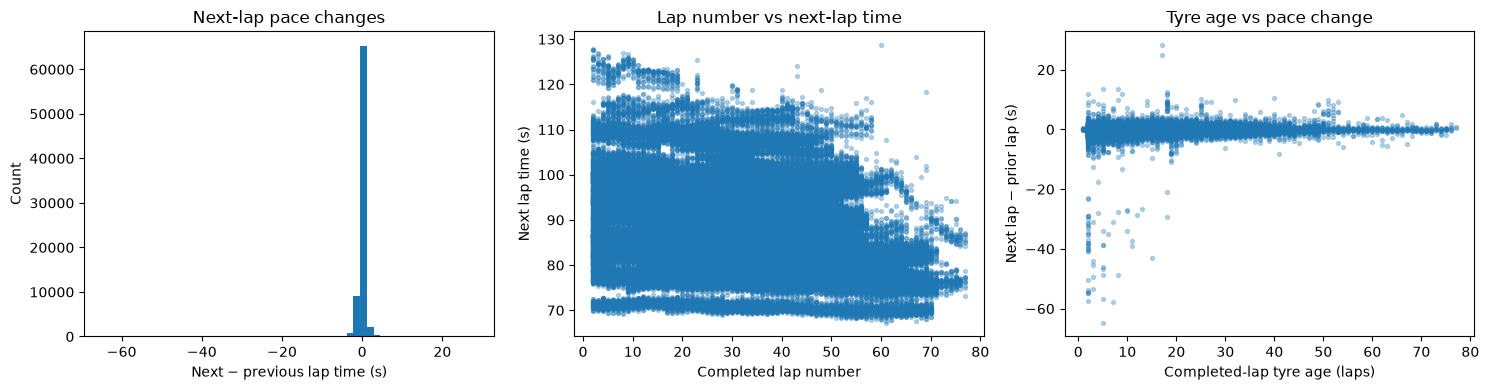

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(clean["DeltaLapTime_s"], bins=55)
axes[0].set(xlabel="Next − previous lap time (s)", ylabel="Count", title="Next-lap pace changes")
axes[1].scatter(clean["PreviousLapNumber"], clean["NextLapTime_s"], s=8, alpha=.3)
axes[1].set(xlabel="Completed lap number", ylabel="Next lap time (s)", title="Lap number vs next-lap time")
axes[2].scatter(clean["TyreAge_laps"], clean["DeltaLapTime_s"], s=8, alpha=.3)
axes[2].set(xlabel="Completed-lap tyre age (laps)", ylabel="Next lap − prior lap (s)", title="Tyre age vs pace change")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_overview.png", dpi=160)
plt.show()

## 8 | Lock race/season-separated train / validation / test groups

In [24]:
def split_by_season(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Fixed chronological seasons, with no shared event IDs across splits."""
    train = df.loc[df["Year"].isin(TRAIN_YEARS)].copy()
    val = df.loc[df["Year"].isin(VAL_YEARS)].copy()
    test = df.loc[df["Year"].isin(TEST_YEARS)].copy()
    groups = [set(zip(t["Year"], t["Event"], t["Session"])) for t in (train,val,test)]
    assert not (groups[0] & groups[1] or groups[0] & groups[2] or groups[1] & groups[2]), "Event leakage"
    if train.empty or val.empty:
        raise ValueError("Insufficient seasons for training/validation. Update TRAIN_YEARS and VAL_YEARS "
            "to disjoint, chronological seasons you have actually downloaded; do not row-random-split.")
    if max(TRAIN_YEARS) >= min(VAL_YEARS) or max(VAL_YEARS) >= min(TEST_YEARS):
        raise ValueError("Season order must be TRAIN < VALIDATION < TEST.")
    return train, val, test

train_df, val_df, test_df = split_by_season(clean)
manifest = {"train": {"years": list(TRAIN_YEARS), "rows": len(train_df)},
            "validation": {"years": list(VAL_YEARS), "rows": len(val_df)},
            "test": {"years": list(TEST_YEARS), "rows": len(test_df)}}
(METRIC_DIR / "split_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))
if test_df.empty:
    print("NOTE: holdout data not present. Validation works; no final generalisation claim possible.")

{
  "train": {
    "years": [
      2022,
      2023
    ],
    "rows": 35872
  },
  "validation": {
    "years": [
      2024
    ],
    "rows": 21394
  },
  "test": {
    "years": [
      2025
    ],
    "rows": 20662
  }
}


## 9 | Model feature sets and preprocessing

**A**: persistence baseline: `next = previous`.

**B**: observed previous lap time + tyre compound/age + track temperature + completed lap index + circuit/event identity.

**C**: B plus **previous-lap** average/max speed, full throttle and braking percentages.

`Year`, `Driver`, `Stint`, `SourceFile`, target-lap identifiers and target-lap data are deliberately **excluded** from model inputs. Categorical unknowns are ignored on held-out circuits. All imputers/scalers/encoders are fit only on the training split.

In [25]:
BASE_NUM = ["PreviousLapTime_s", "TyreAge_laps", "TrackTemp_C", "PreviousLapNumber"]
BASE_CAT = ["TyreCompound", "Event"]
TELEM_NUM = ["AvgSpeed_kmh", "MaxSpeed_kmh", "FullThrottle_pct", "Braking_pct"]
FEATURE_SETS = {"B_context": (BASE_NUM, BASE_CAT), "C_telemetry": (BASE_NUM + TELEM_NUM, BASE_CAT)}

def make_pipeline(model, numerical: list[str], categorical: list[str]) -> Pipeline:
    """Return preprocessing and regression pipeline fit on training rows only."""
    num = Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                    ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("numeric", num, numerical), ("categorical", cat, categorical)])
    return Pipeline([("preprocessor", prep), ("regressor", model)])

def candidate_models():
    """Compact validation grid; bounded for a student laptop CPU."""
    return {
        "LinearRegression": [("default", LinearRegression())],
        "DecisionTree": [(f"depth={d},leaf={leaf}", DecisionTreeRegressor(
            max_depth=d, min_samples_leaf=leaf, random_state=SEED))
            for d in [5, 10] for leaf in [5, 15]],
        "RandomForest": [(f"trees={trees},leaf={leaf}", RandomForestRegressor(
            n_estimators=trees, min_samples_leaf=leaf, n_jobs=-1, random_state=SEED))
            for trees in [75, MAX_RF_TREES] for leaf in [5, 15]]
    }

if REQUIRE_TELEMETRY and clean[TELEM_NUM].isna().any(axis=1).any():
    raise ValueError("Required telemetry missing. Fix exporter or set REQUIRE_TELEMETRY=False.")
if clean[TELEM_NUM].notna().sum().sum() == 0:
    print("WARNING: No previous-lap telemetry detected. C ablation is mathematically uninformative; do not claim telemetry benefits.")

## 10 | Train candidates and tune on validation **only**

In [26]:
def prepare_model_inputs(df, numeric, categorical):

    X = df[numeric + categorical].copy()

    # Convert nullable numeric columns to standard float64.
    # Missing values become np.nan.
    for col in numeric:
        X[col] = pd.to_numeric(
            X[col], errors="coerce"
        ).astype("float64")

    # Convert categorical missing values into ordinary strings.
    for col in categorical:
        X[col] = (
            X[col]
            .astype("object")
            .where(X[col].notna(), "Unknown")
            .astype(str)
        )

    return X


def evaluate_split(df: pd.DataFrame, predicted_delta: np.ndarray) -> dict[str,float]:
    """Evaluate reconstructed next-lap seconds and delta seconds."""
    actual_next = df["NextLapTime_s"].to_numpy(dtype=float)
    previous = df["PreviousLapTime_s"].to_numpy(dtype=float)
    predicted_next = previous + np.asarray(predicted_delta, dtype=float)
    return {"MAE_s": mean_absolute_error(actual_next, predicted_next),
            "RMSE_s": np.sqrt(mean_squared_error(actual_next, predicted_next)),
            "R2_next_lap": r2_score(actual_next, predicted_next),
            "MAE_delta_s": mean_absolute_error(df["DeltaLapTime_s"], predicted_delta)}

rows = []
valid_pred = {}
fitted = {}
base_delta = np.zeros(len(val_df))
rows.append({"features": "A_persistence", "model": "Persistence", "params": "none",
             "fit_seconds": 0., "predict_seconds": 0., **evaluate_split(val_df, base_delta)})
valid_pred[("A_persistence", "Persistence", "none")] = base_delta
for feature_name, (numeric, categorical) in FEATURE_SETS.items():
    for model_name, variants in candidate_models().items():
        for params, regressor in variants:
            pipeline = make_pipeline(regressor, numeric, categorical)
            start = time.perf_counter()
            
            X_train = prepare_model_inputs(train_df, numeric, categorical)
            X_val = prepare_model_inputs(val_df, numeric, categorical)
            y_train = pd.to_numeric(train_df["DeltaLapTime_s"], errors="raise").to_numpy(dtype="float64")
            pipeline.fit(X_train, y_train)
            fit_duration = time.perf_counter() - start
            start = time.perf_counter()
            delta_pred = pipeline.predict(val_df[numeric + categorical])
            pred_duration = time.perf_counter() - start
            key = (feature_name, model_name, params)
            fitted[key] = pipeline
            valid_pred[key] = delta_pred
            rows.append({"features": feature_name, "model": model_name,
                         "params": params, "fit_seconds": fit_duration,
                         "predict_seconds": pred_duration,
                         **evaluate_split(val_df, delta_pred)})
comparison = pd.DataFrame(rows).sort_values(["MAE_s", "RMSE_s"]).reset_index(drop=True)
comparison.to_csv(METRIC_DIR / "validation_grid.csv", index=False)
display(comparison.round(4))

,features,model,params,fit_seconds,predict_seconds,MAE_s,RMSE_s,R2_next_lap,MAE_delta_s
0,A_persistence,Persistence,none,0.0000,0.0000,0.4645,1.0512,0.9891,0.4645
1,C_telemetry,DecisionTree,"depth=5,leaf=15",0.1593,0.0220,0.4696,0.8791,0.9924,0.4696
2,C_telemetry,DecisionTree,"depth=5,leaf=5",0.1478,0.0207,0.4794,1.0624,0.9889,0.4794
3,C_telemetry,DecisionTree,"depth=10,leaf=15",0.2493,0.0232,0.4903,0.9534,0.9911,0.4903
4,B_context,DecisionTree,"depth=5,leaf=15",0.2622,0.0444,0.5046,0.9851,0.9905,0.5046
5,C_telemetry,DecisionTree,"depth=10,leaf=5",0.2450,0.0205,0.5052,1.1420,0.9872,0.5052
6,B_context,DecisionTree,"depth=5,leaf=5",0.2008,0.0432,0.5062,1.0086,0.9900,0.5062
7,C_telemetry,RandomForest,"trees=150,leaf=15",9.9397,0.0984,0.5126,0.9158,0.9918,0.5126
8,C_telemetry,RandomForest,"trees=75,leaf=15",5.0000,0.0913,0.5141,0.9188,0.9917,0.5141
9,B_context,DecisionTree,"depth=10,leaf=5",0.3576,0.0417,0.5405,1.1165,0.9877,0.5405


## 11 | Model selection and telemetry ablation

Choose the **lowest validation MAE**, including persistence as an eligible winner. Compare the best B and C configurations on the same validation rows. A telemetry improvement is an *association*, not proof of physical causation. Do not select models using 2025 results.

Selected from validation: ('A_persistence', 'Persistence', 'none') | MAE (s): 0.4645


,features,model,params,MAE_s,RMSE_s,R2_next_lap
0,B_context,DecisionTree,"depth=5,leaf=15",0.504559,0.985131,0.990459
1,C_telemetry,DecisionTree,"depth=5,leaf=15",0.469607,0.879105,0.992402


Validation telemetry ablation (B MAE - C MAE): +0.0350 s (positive favors telemetry).


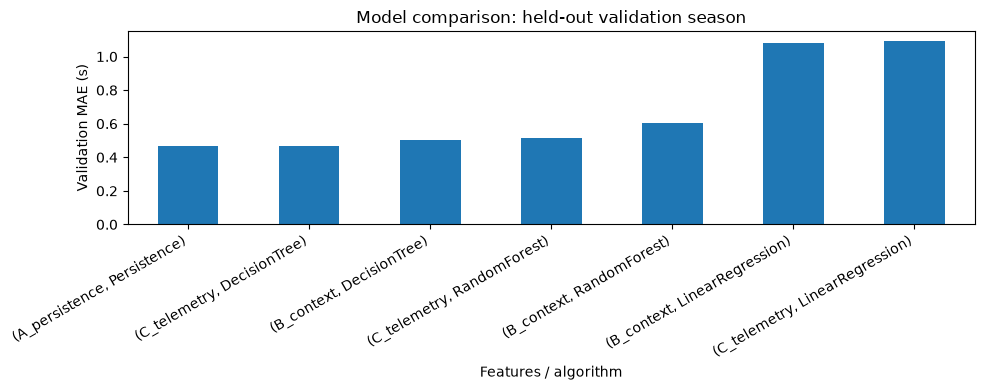

In [27]:
best = comparison.iloc[0]
best_key = (best["features"], best["model"], best["params"])
print("Selected from validation:", best_key, "| MAE (s):", round(best["MAE_s"], 4))
per_family = (comparison[comparison["features"].isin(FEATURE_SETS)]
              .sort_values("MAE_s").groupby("features", as_index=False).first())
display(per_family[["features", "model", "params", "MAE_s", "RMSE_s", "R2_next_lap"]])
if len(per_family) == 2:
    b_err = per_family.set_index("features").loc["B_context", "MAE_s"]
    c_err = per_family.set_index("features").loc["C_telemetry", "MAE_s"]
    print(f"Validation telemetry ablation (B MAE - C MAE): {b_err-c_err:+.4f} s (positive favors telemetry).")

fig, ax = plt.subplots(figsize=(10, 4))
comparison.groupby(["features", "model"])["MAE_s"].min().sort_values().plot.bar(ax=ax)
ax.set(xlabel="Features / algorithm", ylabel="Validation MAE (s)", title="Model comparison: held-out validation season")
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "validation_mae_comparison.png", dpi=160)
plt.show()

## 12 | Validation residual diagnostics and engineering breakdown

,Year,Event,Session,Driver,Stint,PreviousLapNumber,TargetLapNumber,TyreCompound,TyreAge_laps,PreviousLapTime_s,NextLapTime_s,PredictedDeltaLapTime_s,PredictedNextLapTime_s,Residual_s,AbsoluteError_s
35872,2024,Abu Dhabi Grand Prix,Race,ALB,1.0,4,5,MEDIUM,4.0,90.060,90.369,0.0,90.060,0.309,0.309
35873,2024,Abu Dhabi Grand Prix,Race,ALB,1.0,5,6,MEDIUM,5.0,90.369,90.815,0.0,90.369,0.446,0.446
35874,2024,Abu Dhabi Grand Prix,Race,ALB,1.0,6,7,MEDIUM,6.0,90.815,90.317,0.0,90.815,-0.498,0.498
35875,2024,Abu Dhabi Grand Prix,Race,ALB,1.0,7,8,MEDIUM,7.0,90.317,90.705,0.0,90.317,0.388,0.388
35876,2024,Abu Dhabi Grand Prix,Race,ALB,1.0,8,9,MEDIUM,8.0,90.705,90.469,0.0,90.705,-0.236,0.236


n  MAE_s  Bias_s
Year Event                                         
2024 Abu Dhabi Grand Prix        821  0.302   0.022
     Australian Grand Prix       785  0.364  -0.013
     Austrian Grand Prix        1152  0.328   0.040
     Azerbaijan Grand Prix       800  0.433  -0.044
     Bahrain Grand Prix          931  0.313   0.053
     Belgian Grand Prix          663  0.329  -0.010
     British Grand Prix          787  1.078   0.169
     Canadian Grand Prix         773  0.950  -0.528
     Chinese Grand Prix          684  0.308   0.062
     Dutch Grand Prix           1308  0.391   0.003
     Emilia Romagna Grand Prix  1118  0.421   0.017
     Hungarian Grand Prix       1155  0.408   0.026
     Italian Grand Prix          877  0.396  -0.022
     Japanese Grand Prix         696  0.766  -0.262
     Las Vegas Grand Prix        760  0.472   0.014
     Mexico City Grand Prix     1021  0.397   0.016
     Miami Grand Prix            865  0.329  -0.042
     Monaco Grand Prix          1134  0.679  -0.123
     Qatar Grand Prix            624  0.351  -0.119
     Saudi Arabian Grand Prix    760  0.431  -0.136
     Singapore Grand Prix       1066  0.449   0.029
     Spanish Grand Prix         1144  0.449   0.050
     São Paulo Grand Prix        668  0.543  -0.244
     United States Grand Prix    802  0.404  -0.039

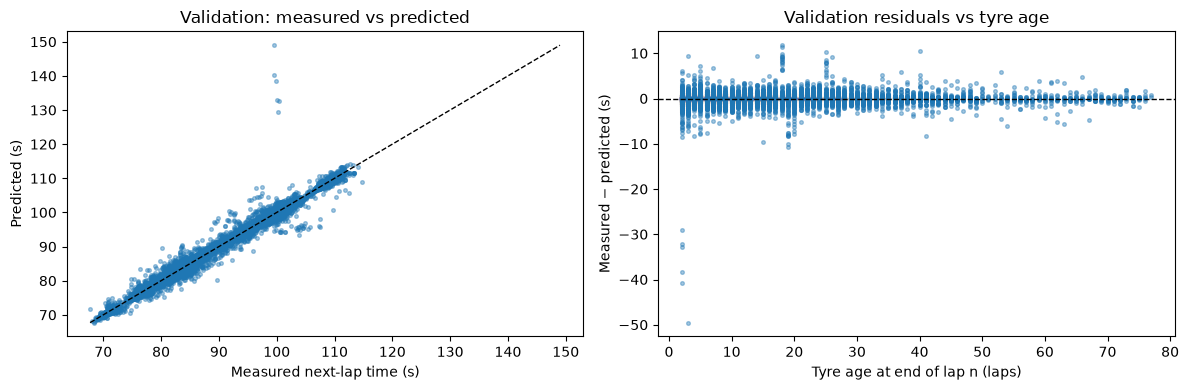

In [28]:
def prediction_frame(frame: pd.DataFrame, pred_delta: np.ndarray) -> pd.DataFrame:
    """Create auditable per-lap records from a split and delta predictions."""
    keep = ["Year", "Event", "Session", "Driver", "Stint", "PreviousLapNumber",
            "TargetLapNumber", "TyreCompound", "TyreAge_laps", "PreviousLapTime_s", "NextLapTime_s"]
    out = frame[keep].copy()
    out["PredictedDeltaLapTime_s"] = pred_delta
    out["PredictedNextLapTime_s"] = out["PreviousLapTime_s"] + pred_delta
    out["Residual_s"] = out["NextLapTime_s"] - out["PredictedNextLapTime_s"]
    out["AbsoluteError_s"] = out["Residual_s"].abs()
    return out

val_predictions = prediction_frame(val_df, valid_pred[best_key])
val_predictions.to_csv(PRED_DIR / "validation_predictions.csv", index=False)
display(val_predictions.head())
display(val_predictions.groupby(["Year", "Event"]).agg(
    n=("AbsoluteError_s", "size"), MAE_s=("AbsoluteError_s", "mean"),
    Bias_s=("Residual_s", "mean")).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(val_predictions["NextLapTime_s"], val_predictions["PredictedNextLapTime_s"], s=7, alpha=.4)
limits = [min(val_predictions["NextLapTime_s"].min(), val_predictions["PredictedNextLapTime_s"].min()),
          max(val_predictions["NextLapTime_s"].max(), val_predictions["PredictedNextLapTime_s"].max())]
ax[0].plot(limits, limits, "k--", lw=1)
ax[0].set(xlabel="Measured next-lap time (s)", ylabel="Predicted (s)", title="Validation: measured vs predicted")
ax[1].scatter(val_predictions["TyreAge_laps"], val_predictions["Residual_s"], s=7, alpha=.4)
ax[1].axhline(0, color="k", ls="--", lw=1)
ax[1].set(xlabel="Tyre age at end of lap n (laps)", ylabel="Measured − predicted (s)", title="Validation residuals vs tyre age")
fig.tight_layout(); fig.savefig(FIG_DIR / "validation_diagnostics.png", dpi=160); plt.show()

## 13 | Runtime, sensitivity and robustness

In [29]:
# Compare fitted cost and validation error across tree complexity settings.
complexity = comparison.loc[comparison["model"].isin(["DecisionTree", "RandomForest"])].copy()
display(complexity[["features", "model", "params", "MAE_s", "fit_seconds", "predict_seconds"]].sort_values("MAE_s").round(4))
# Percent improvement relative to persistence: a negative result is valid and must be reported.
persist_mae = float(comparison.loc[comparison["model"] == "Persistence", "MAE_s"].iloc[0])
relative_gain = 100. * (persist_mae - float(best["MAE_s"])) / persist_mae if persist_mae else float("nan")
print(f"MAE improvement over previous-lap persistence (validation): {relative_gain:+.2f}%")

,features,model,params,MAE_s,fit_seconds,predict_seconds
1,C_telemetry,DecisionTree,"depth=5,leaf=15",0.4696,0.1593,0.0220
2,C_telemetry,DecisionTree,"depth=5,leaf=5",0.4794,0.1478,0.0207
3,C_telemetry,DecisionTree,"depth=10,leaf=15",0.4903,0.2493,0.0232
4,B_context,DecisionTree,"depth=5,leaf=15",0.5046,0.2622,0.0444
5,C_telemetry,DecisionTree,"depth=10,leaf=5",0.5052,0.2450,0.0205
6,B_context,DecisionTree,"depth=5,leaf=5",0.5062,0.2008,0.0432
7,C_telemetry,RandomForest,"trees=150,leaf=15",0.5126,9.9397,0.0984
8,C_telemetry,RandomForest,"trees=75,leaf=15",0.5141,5.0000,0.0913
9,B_context,DecisionTree,"depth=10,leaf=5",0.5405,0.3576,0.0417
10,C_telemetry,RandomForest,"trees=150,leaf=5",0.5450,17.4118,0.1092


MAE improvement over previous-lap persistence (validation): +0.00%


## 14 | Reserve final 2025 holdout until model selection is frozen

Run only after validation-based decisions are final. This evaluates **exactly once** against held-out events from 2025, if your local dataset contains them. This notebook retains the model fit on 2022–23 only (no inadvertent test fitting). In a later, explicitly documented production step you may refit on train+validation, but do not conflate that with these holdout figures.

In [30]:
# ============================================================
# MMA3001 - FINAL INDEPENDENT 2025 HOLDOUT EVALUATION
# ============================================================

if RUN_FINAL_TEST:

    if test_df.empty:
        raise ValueError(
            "No 2025 holdout data found. Check the dataset and season split."
        )

    print("Selected model:", best_key)
    print("Holdout observations:", len(test_df))

    # Persistence baseline requires no fitted model.
    if best_key[1] == "Persistence":
        test_delta = np.zeros(len(test_df), dtype=float)

    else:
        # Apply the same feature preparation used during training.
        numeric, categorical = FEATURE_SETS[best_key[0]]

        X_test = prepare_model_inputs(
            test_df,
            numeric,
            categorical,
        )

        # Model was fitted using training observations only.
        test_delta = fitted[best_key].predict(X_test)

    # Evaluate reconstructed next-lap times.
    test_score = evaluate_split(test_df, test_delta)

    # Generate per-lap prediction records.
    test_predictions = prediction_frame(test_df, test_delta)

    # Save results.
    test_predictions.to_csv(
        PRED_DIR / "FINAL_holdout_2025_predictions.csv",
        index=False,
    )

    metrics = {
        "selected_model": list(best_key),
        "selection_metric": "2024 validation MAE",
        "holdout_year": 2025,
        "observations": len(test_df),
        "scores": {
            key: float(value)
            for key, value in test_score.items()
        },
    }

    (METRIC_DIR / "FINAL_holdout_2025_metrics.json").write_text(
        json.dumps(metrics, indent=2),
        encoding="utf-8",
    )

    print("\nFINAL 2025 HOLDOUT RESULTS")
    display(pd.DataFrame([test_score]).round(4))

    print("\nPER-CIRCUIT PERFORMANCE")
    display(
        test_predictions.groupby(["Year", "Event"]).agg(
            Observations=("AbsoluteError_s", "size"),
            MAE_s=("AbsoluteError_s", "mean"),
            Bias_s=("Residual_s", "mean"),
        ).round(4)
    )

else:
    print(
        "Final 2025 holdout remains locked. "
        "Freeze model selection before enabling."
    )

Selected model: ('A_persistence', 'Persistence', 'none')
Holdout observations: 20662

FINAL 2025 HOLDOUT RESULTS


,MAE_s,RMSE_s,R2_next_lap,MAE_delta_s
0,0.3862,0.6798,0.9958,0.3862



PER-CIRCUIT PERFORMANCE


Observations   MAE_s  Bias_s
Year Event                                                  
2025 Abu Dhabi Grand Prix               1035  0.3163  0.0097
     Australian Grand Prix               494  0.7748 -0.5081
     Austrian Grand Prix                 934  0.3589  0.0120
     Azerbaijan Grand Prix               725  0.4138 -0.1149
     Bahrain Grand Prix                  885  0.3806  0.0582
     Belgian Grand Prix                  701  0.4736 -0.0557
     British Grand Prix                  374  0.7143 -0.2518
     Canadian Grand Prix                1097  0.3310 -0.0043
     Chinese Grand Prix                  876  0.3094  0.0018
     Dutch Grand Prix                    886  0.3208 -0.0667
     Emilia Romagna Grand Prix           875  0.3863 -0.0282
     Hungarian Grand Prix               1240  0.3772 -0.0007
     Italian Grand Prix                  844  0.2598 -0.0512
     Japanese Grand Prix                 956  0.2667 -0.0449
     Las Vegas Grand Prix                712  0.2963 -0.0555
     Mexico City Grand Prix             1019  0.3417  0.0200
     Miami Grand Prix                    493  0.2656  0.0203
     Monaco Grand Prix                  1088  0.6644 -0.0071
     Qatar Grand Prix                    861  0.2563 -0.0555
     Saudi Arabian Grand Prix            776  0.3557 -0.0415
     Singapore Grand Prix               1044  0.5819 -0.0263
     Spanish Grand Prix                  914  0.4364  0.0172
     São Paulo Grand Prix                981  0.3015  0.0668
     United States Grand Prix            852  0.3384  0.0092

In [31]:
# ============================================================
# FINAL HOLDOUT - PERSISTENCE BENCHMARK
# ============================================================

baseline_delta = np.zeros(len(test_df), dtype=float)

baseline_score = evaluate_split(
    test_df,
    baseline_delta,
)

comparison_holdout = pd.DataFrame([
    {"Model": "Persistence baseline", **baseline_score},
    {"Model": "Selected final model", **test_score},
])

display(comparison_holdout.round(4))

baseline_mae = baseline_score["MAE_s"]
selected_mae = test_score["MAE_s"]

if baseline_mae > 0:
    improvement = (
        (baseline_mae - selected_mae)
        / baseline_mae
        * 100
    )
    print(f"MAE improvement over persistence: {improvement:+.2f}%")

,Model,MAE_s,RMSE_s,R2_next_lap,MAE_delta_s
0,Persistence baseline,0.3862,0.6798,0.9958,0.3862
1,Selected final model,0.3862,0.6798,0.9958,0.3862


MAE improvement over persistence: +0.00%


## 15 | Save selected model, versions and reproducibility manifest

## 15. Engineering Error Analysis — 2025 Holdout

### Objective
Investigate how next-lap prediction errors vary across Formula 1 circuits,
drivers, tyre compounds, tyre age, and race progression.

### Method
Use the frozen 2025 holdout predictions without retraining or tuning.

### Engineering Questions
1. Which circuits are most difficult to predict?
2. Do prediction errors vary between drivers?
3. How does tyre compound affect prediction accuracy?
4. Does tyre degradation influence prediction errors?
5. Are larger errors concentrated at particular stages of a race?

### Limitations
The results describe associations, not causal effects.
Only retrospectively eligible clean racing laps are included.

In [32]:
# ============================================================
# SECTION 15.1 — HOLDOUT ERROR ANALYSIS DATASET
# ============================================================
# Use the frozen 2025 holdout predictions.
# Do not refit models or alter their parameters here.

if "test_predictions" not in globals():
    raise RuntimeError(
        "Run the final 2025 holdout evaluation first."
    )

analysis = test_predictions.copy()

if analysis.empty:
    raise ValueError("No 2025 predictions available.")

assert set(analysis["Year"].astype(int)) == {2025}

analysis["Residual_s"] = (
    analysis["NextLapTime_s"]
    - analysis["PredictedNextLapTime_s"]
)

analysis["AbsoluteError_s"] = analysis["Residual_s"].abs()
analysis["SquaredError_s2"] = analysis["Residual_s"] ** 2

# Race progress represented by lap number.
analysis["RaceLap"] = analysis["TargetLapNumber"]

print("2025 observations:", len(analysis))
print("Circuits:", analysis["Event"].nunique())
print("Drivers:", analysis["Driver"].nunique())

display(analysis.head())

2025 observations: 20662
Circuits: 24
Drivers: 21


,Year,Event,Session,Driver,Stint,PreviousLapNumber,TargetLapNumber,TyreCompound,TyreAge_laps,PreviousLapTime_s,NextLapTime_s,PredictedDeltaLapTime_s,PredictedNextLapTime_s,Residual_s,AbsoluteError_s,SquaredError_s2,RaceLap
57266,2025,Abu Dhabi Grand Prix,Race,ALB,1.0,2,3,SOFT,2.0,91.710,90.224,0.0,91.710,-1.486,1.486,2.208196,3
57267,2025,Abu Dhabi Grand Prix,Race,ALB,1.0,3,4,SOFT,3.0,90.224,90.874,0.0,90.224,0.650,0.650,0.422500,4
57268,2025,Abu Dhabi Grand Prix,Race,ALB,1.0,4,5,SOFT,4.0,90.874,90.314,0.0,90.874,-0.560,0.560,0.313600,5
57269,2025,Abu Dhabi Grand Prix,Race,ALB,1.0,5,6,SOFT,5.0,90.314,90.223,0.0,90.314,-0.091,0.091,0.008281,6
57270,2025,Abu Dhabi Grand Prix,Race,ALB,1.0,6,7,SOFT,6.0,90.223,90.420,0.0,90.223,0.197,0.197,0.038809,7


## 16 | Engineer's conclusion and limitations — fill in after execution

1. **Baseline:** State persistence MAE in seconds.
2. **Selected method:** Identify model, configuration and validation MAE/RMSE/R²; compare compute time.
3. **Telemetry contribution:** Report B vs C MAE on identical observations; **do not claim a telemetry benefit if the exporter contains no telemetry**.
4. **Generalisability:** If the holdout was enabled, show independent 2025 event-level errors, not only pooled accuracy.
5. **Physical meaning:** Explain tyres, temperature, traffic, fuel mass and circuit effects, acknowledging confounding and unobserved conditions.
6. **Research boundaries:** Retrospectively clean target laps, no guaranteed forecasting of pits/neutralisation; unknown circuits and sparse operating regions warrant caution.
7. **Data provenance:** Source is FastF1 historical timing/telemetry; audit export logic separately for timestamp and track-status leakage.
8. **AI use:** Document ChatGPT-generated code structure, student validation, corrections and decisions in your report. Your MMA3001 brief requires explicit AI-use reflection.

### Further scope (not included in assessed P0)
Tyre-strategy optimisation needs a **separate future-pace model** and explicit pit-loss assumptions. Do **not** feed unknown future telemetry through this single-step model recursively. The development plan treats race strategy as a conditional extension once core validation passes.

### Reproducibility checklist
- [ ] Existing exporter checked for weather time and previous-lap-only telemetry
- [ ] At least two distinct real races and chronology established
- [ ] All invalid pairs and missing values quantified
- [ ] Model selection conducted without reading test errors
- [ ] Test executed once and results interpreted per event
- [ ] CSV and model outputs not published contrary to data rights
- [ ] GitHub README, source docstrings, tests/HTML docs and AI reflection finalized